# 00 · Data acquisition and verification

> **What and why**
>
> - We list every dataset we downloaded, where it came from and how big it is.
> - We prove the FIRMS copy we use matches NASA's official files row by row.
> - We check that every file is real, complete data.
> - Everything later in the project depends on this step, so we show it openly.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()

## 1. The download log

Every file we downloaded is recorded in `manifest.csv`, with its source link, the time we downloaded it, its size and a SHA-256 checksum. A checksum is a fingerprint of the file. If even one byte changes, the fingerprint changes.

In [2]:
m = pd.read_csv(C.raw('manifest.csv'))
summary = (m.groupby('dataset').agg(files=('file', 'count'), gigabytes=('bytes', lambda b: round(b.sum() / 1e9, 2)))
             .sort_values('gigabytes', ascending=False))
print(f"{len(m):,} files, {m.bytes.sum() / 1e9:.1f} GB in total")
summary

14,480 files, 46.4 GB in total


,files,gigabytes
dataset,,
gpm_imerg_late_daily,401,12.19
gpm_imerg_monthly,309,5.80
landcover_mcd12c1,4,4.98
gfwed_fwi_sampled,584,2.52
indonesia_viirs_ahi_emissions,2,2.42
merra2_aer_monthly,321,1.27
firms/year=2024,1,1.22
merra2_cnn_pm25_seasia,3672,1.10
firms/year=2025,1,1.03


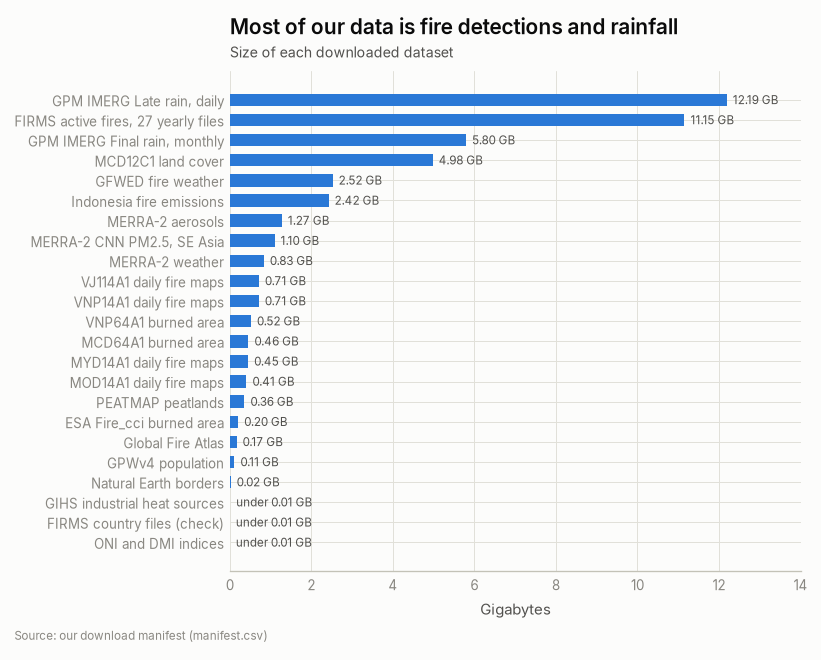

In [3]:
NAMES = {'firms': 'FIRMS active fires, 27 yearly files', 'gpm_imerg_late_daily': 'GPM IMERG Late rain, daily',
         'gpm_imerg_monthly': 'GPM IMERG Final rain, monthly', 'landcover_mcd12c1': 'MCD12C1 land cover',
         'gfwed_fwi_sampled': 'GFWED fire weather', 'indonesia_viirs_ahi_emissions': 'Indonesia fire emissions',
         'merra2_aer_monthly': 'MERRA-2 aerosols', 'merra2_cnn_pm25_seasia': 'MERRA-2 CNN PM2.5, SE Asia',
         'merra2_slv_monthly': 'MERRA-2 weather', 'firemap_vnp14a1': 'VNP14A1 daily fire maps', 'firemap_vj114a1': 'VJ114A1 daily fire maps',
         'firemap_myd14a1': 'MYD14A1 daily fire maps', 'firemap_mod14a1': 'MOD14A1 daily fire maps', 'burned_vnp64a1': 'VNP64A1 burned area',
         'burned_mcd64a1': 'MCD64A1 burned area', 'peatmap': 'PEATMAP peatlands', 'esa_firecci_grid': 'ESA Fire_cci burned area',
         'global_fire_atlas': 'Global Fire Atlas', 'population_gpwv4': 'GPWv4 population', 'natural_earth': 'Natural Earth borders',
         'gihs': 'GIHS industrial heat sources', 'climate_indices': 'ONI and DMI indices', 'firms_validation': 'FIRMS country files (check)'}
grouped = (m.assign(group=m.dataset.str.replace(r'/year=\d{4}', '', regex=True))
             .groupby('group').agg(gigabytes=('bytes', lambda b: b.sum() / 1e9)))
grouped.index = [NAMES.get(g, g) for g in grouped.index]
fig, ax = plt.subplots(figsize=fh.SIZE['full_tall'])
s = grouped.sort_values('gigabytes')
ax.barh(s.index, s.gigabytes, color=fh.SENSOR['MODIS'], height=0.62)
for y, v in enumerate(s.gigabytes):
    ax.text(v, y, f'  {v:.2f} GB' if v >= 0.01 else '  under 0.01 GB', va='center', fontsize=7, color=fh.INK_2)
fh.clean(ax, grid_axis='x'); ax.set_xlabel('Gigabytes'); ax.set_xlim(0, s.gigabytes.max() * 1.15)
fh.title(ax, 'Most of our data is fire detections and rainfall', 'Size of each downloaded dataset')
fh.source(fig, 'Source: our download manifest (manifest.csv)')
fh.save(fig, FIG / 'fig00_data_volume')

## 2. Does our FIRMS copy match NASA's official files?

We use a free copy of the full FIRMS archive (640 million rows) because it is fast to query. To trust it, we took official country files straight from NASA FIRMS and looked up **every row** in our copy, matching on location, date and time.

In [4]:
V = C.raw('firms_validation')
checks = [('Malaysia 2023', 'MODIS', 'modis_2023_Malaysia.csv', 2023, (99, 120, 0, 8)),
          ('Malaysia 2023', 'VIIRS_SNPP', 'viirs-snpp_2023_Malaysia.csv', 2023, (99, 120, 0, 8)),
          ('Malaysia 2023', 'VIIRS_NOAA20', 'viirs-jpss1_2023_Malaysia.csv', 2023, (99, 120, 0, 8)),
          ('Argentina 2005', 'MODIS', 'modis_2005_Argentina.csv', 2005, (-75, -52, -56, -21)),
          ('Argentina 2015', 'VIIRS_SNPP', 'viirs-snpp_2015_Argentina.csv', 2015, (-75, -52, -56, -21))]
rows = []
for place, sensor, f, y, (x0, x1, y0, y1) in checks:
    n_off, n_found = con.execute(f'''
      WITH o AS (SELECT round(latitude,4) lat, round(longitude,4) lon, acq_date::DATE d, lpad(acq_time::VARCHAR,4,'0') t FROM read_csv_auto('{V / f}')),
           mm AS (SELECT round(ST_Y(geometry),4) lat, round(ST_X(geometry),4) lon, acq_date d, strftime(acq_datetime,'%H%M') t
                  FROM '{C.raw('firms', f'year={y}', 'detections.parquet')}' WHERE sensor='{sensor}' AND ST_X(geometry) BETWEEN {x0} AND {x1} AND ST_Y(geometry) BETWEEN {y0} AND {y1})
      SELECT count(*), count(mm.lat) FROM o LEFT JOIN mm USING (lat, lon, d, t)''').fetchall()[0]
    rows.append({'official file': f'{place}, {sensor}', 'official rows': n_off, 'found in our copy': n_found, 'match': f'{100 * n_found / n_off:.2f}%'})
pd.DataFrame(rows)

,official file,official rows,found in our copy,match
0,"Malaysia 2023, MODIS",2310,2310,100.00%
1,"Malaysia 2023, VIIRS_SNPP",8268,8268,100.00%
2,"Malaysia 2023, VIIRS_NOAA20",8600,8600,100.00%
3,"Argentina 2005, MODIS",71179,71179,100.00%
4,"Argentina 2015, VIIRS_SNPP",151089,151089,100.00%


## 3. Is every file real, complete data?

A download can fail quietly and leave an error page or a half file. We read the first bytes of every file and check its format signature. We also open every fire weather file fully.

In [5]:
import subprocess
print(subprocess.run([sys.executable, str(Path.home() / 'nasa_work/scripts/verify_raw.py')], capture_output=True, text=True).stdout[-1500:])

folder                              files     size  types
burned_mcd64a1                        120    0.46G  {'hdf4': 120}
burned_vnp64a1                        120    0.52G  {'hdf4': 120}
climate_indices                         2    0.00G  {'text': 2}
esa_firecci_grid                      264    0.20G  {'hdf5/netcdf4': 264}
firms_validation                        5    0.02G  {'text': 5}
gihs                                    1    0.01G  {'zip': 1}
global_fire_atlas                      98    0.17G  {'geotiff': 98}
indonesia_viirs_ahi_emissions           2    2.42G  {'text': 2}
landcover_mcd12c1                       4    4.98G  {'hdf4': 4}
natural_earth                           2    0.02G  {'zip': 2}
peatmap                                 6    0.36G  {'zip': 6}
population_gpwv4                        5    0.11G  {'zip': 5}
firms (27 yearly parquet files)        27   11.15G  {'parquet': 27}

TOTAL 656 files, 20.4 GB; problems: 0



> **Key findings**
>
> - We hold about 44 GB of free NASA, ESA and NOAA data, all logged with checksums.
> - Our FIRMS copy matches NASA's official files exactly: 100% of rows found, on two continents and across three sensor eras.
> - Every file passed the integrity check, so the rest of the project starts from clean, trusted data.